In [1]:
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import models

## 1. Load the pretrained networks

In [2]:
zoo = {
    "VGG16":     models.vgg16(weights="DEFAULT"),
    "ResNet50":  models.resnet50(weights="DEFAULT"),
    "GoogLeNet": models.googlenet(weights="DEFAULT"),
}
for name, net in zoo.items():
    net.eval()
    print(f"{name} loaded")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 109MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 144MB/s]


Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 168MB/s]

VGG16 loaded
ResNet50 loaded
GoogLeNet loaded


## 2. Collect statistics

In [3]:
def count_params(net):
    return sum(p.numel() for p in net.parameters())

def count_convs(net):
    return sum(isinstance(m, nn.Conv2d) for m in net.modules())

idea = {
    "VGG16":     "Plain stack of 3x3 convs, very large FC head",
    "ResNet50":  "Residual (skip) connections allow very deep nets",
    "GoogLeNet": "Inception modules, parallel branches, few parameters",
}

table = pd.DataFrame([
    {
        "Model": name,
        "Parameters (M)": count_params(net) / 1e6,
        "Size (MB, fp32)": count_params(net) * 4 / 1024**2,
        "Top-level blocks": len(list(net.children())),
        "Conv layers": count_convs(net),
        "Key idea": idea[name],
    }
    for name, net in zoo.items()
]).round(2)
table

,Model,Parameters (M),"Size (MB, fp32)",Top-level blocks,Conv layers,Key idea
0,VGG16,138.36,527.79,3,13,"Plain stack of 3x3 convs, very large FC head"
1,ResNet50,25.56,97.49,10,53,Residual (skip) connections allow very deep nets
2,GoogLeNet,6.62,25.27,19,57,"Inception modules, parallel branches, few para..."


## 3. Visual comparison

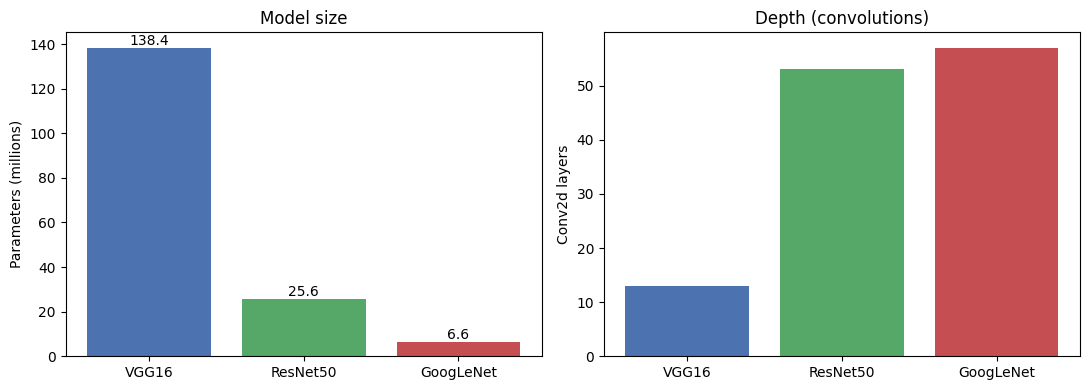

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bars = ax1.bar(table["Model"], table["Parameters (M)"], color=["#4c72b0", "#55a868", "#c44e52"])
ax1.bar_label(bars, fmt="%.1f")
ax1.set(ylabel="Parameters (millions)", title="Model size")
ax2.bar(table["Model"], table["Conv layers"], color=["#4c72b0", "#55a868", "#c44e52"])
ax2.set(ylabel="Conv2d layers", title="Depth (convolutions)")
plt.tight_layout(); plt.show()

## 4. Observations
* **VGG16** has by far the most parameters, mostly in its fully connected head, yet it is the
  shallowest of the three.
* **ResNet50** is much deeper but far smaller, because residual connections make depth
  trainable and its head is a single linear layer.
* **GoogLeNet** is the lightest, thanks to Inception modules and 1x1 bottleneck convolutions.